# 00 - VisionStudio Setup | إعداد البيئة والمشروع

**المقرر:** معالجة الصور والرؤية بالحاسوب - عملي  
**المدرّسة:** د. سمية الشيبة  
**المرحلة:** بكالوريوس ذكاء اصطناعي  

يهدف المشروع إلى بناء تطبيق Android لمعالجة الصور والفيديو والكاميرا المباشرة، مع دعم الفلاتر والتحويلات الهندسية والتقسيم واكتشاف الأجسام، والعمل دون إنترنت بعد تثبيت ملف APK.

## مسار تنفيذ المشروع

1. تنفيذ الخوارزميات واختبارها في Google Colab باستخدام Python وOpenCV.
2. معالجة الصور والفيديو واختبار YOLO26n.
3. تصدير نموذج YOLO إلى LiteRT بصيغة `.tflite`.
4. نقل خوارزميات OpenCV من Python إلى Kotlin.
5. بناء تطبيق Android باستخدام CameraX وOpenCV وLiteRT.
6. إنتاج APK يعمل Offline بالكامل.

## تثبيت المكتبات

تأتي NumPy وMatplotlib وOpenCV مثبتة غالبًا في Colab. الخلية التالية تثبّت فقط المكتبات الناقصة عند الحاجة.

In [1]:
# شغّل هذا الأمر فقط إذا ظهرت مشكلة في استيراد المكتبات
# %pip install -q opencv-python-headless numpy matplotlib

## استيراد المكتبات وفحص البيئة

In [2]:
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print(f'Python: {sys.version.split()[0]}')
print(f'OpenCV: {cv2.__version__}')
print(f'NumPy: {np.__version__}')
print(f'Matplotlib: {matplotlib.__version__}')

Python: 3.13.15
OpenCV: 5.0.0
NumPy: 2.1.3
Matplotlib: 3.10.0


## إنشاء مجلدات العمل

سنستخدم مجلدًا للمدخلات ومجلدًا منفصلًا للنتائج، حتى تبقى ملفات المشروع مرتبة.

In [3]:
from google.colab import drive
from pathlib import Path

# ربط Google Drive
drive.mount("/content/drive")

# مسار المشروع الرئيسي
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "VisionStudio_Android_ImageProcessing"
)

# المسارات الرئيسية
NOTEBOOKS_DIR = PROJECT_ROOT / "01_Notebooks"
IMAGES_INPUT_DIR = PROJECT_ROOT / "02_Data/Images/Input"
IMAGES_TEST_DIR = PROJECT_ROOT / "02_Data/Images/Test"
VIDEOS_INPUT_DIR = PROJECT_ROOT / "02_Data/Videos/Input"
VIDEOS_TEST_DIR = PROJECT_ROOT / "02_Data/Videos/Test"
MODELS_DIR = PROJECT_ROOT / "03_Models"
IMAGES_OUTPUT_DIR = PROJECT_ROOT / "04_Outputs/Images"
VIDEOS_OUTPUT_DIR = PROJECT_ROOT / "04_Outputs/Videos"

print("Project:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())

Mounted at /content/drive
Project: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing
Project exists: True


## العمليات التي سيغطيها المشروع

- إدخال وإخراج الصور والفيديو.
- Grayscale وThresholding.
- Crop وResize وRotate وTranslation.
- الفلاتر وتحسين التباين والحدة.
- اكتشاف الحواف والخطوط والدوائر والزوايا.
- Segmentation وMorphology وعزل العناصر.
- اكتشاف الوجه والعين.
- YOLO26n لاكتشاف الأجسام وYOLO26n-seg للعزل المتقدم.
- نقل الوظائف إلى تطبيق Android يعمل دون إنترنت.

## اختبار بسيط لـOpenCV

ننشىء صورة صغيرة داخل الذاكرة ثم نتأكد من أن OpenCV يستطيع تحويلها إلى Grayscale.

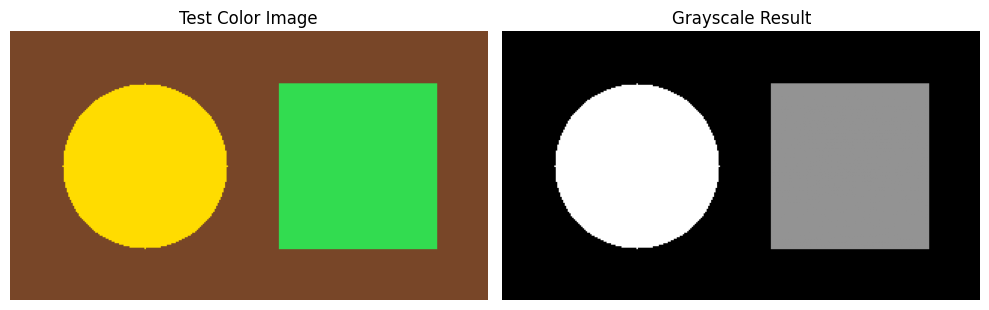

In [4]:
test_image = np.zeros((180, 320, 3), dtype=np.uint8)
test_image[:] = (40, 70, 120)  # BGR
cv2.circle(test_image, (90, 90), 55, (0, 220, 255), -1)
cv2.rectangle(test_image, (180, 35), (285, 145), (80, 220, 50), -1)

test_gray = cv2.cvtColor(test_image, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB))
axes[0].set_title('Test Color Image')
axes[1].imshow(test_gray, cmap='gray')
axes[1].set_title('Grayscale Result')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()

## نتيجة المرحلة التمهيدية

إذا ظهرت الصورتان وطبعت إصدارات المكتبات دون أخطاء، فإن بيئة Colab جاهزة للبدء بتنفيذ خوارزميات المشروع.